# introduction to `pandas`

**pandas** is a Python library for working with tables of data. Its two main types are the **DataFrame**, a
whole table of rows and columns (like the CSV files from Parts 7 and 9), and the **Series**, a single column of
a DataFrame.

In this notebook we'll explore a real dataset: 500 objects from the Metropolitan Museum of Art's collection
whose search matched the word "woman". The data came from the Met's API (see
[Part 10](https://craigfahner.github.io/INFO-664/part10/)) and has been saved as `woman_500.csv`, in the same
folder as this notebook.

pandas is imported under the nickname `pd`. That's the convention you'll see everywhere.

In [1]:
import pandas as pd

### where the data came from

The dataset was collected from the Met's API with the script below, and saved as `woman_500.csv`. It's shown as
plain text so that it **doesn't run** when you run this notebook (it makes about 500 requests to the Met's
servers).

Since the Met introduced version 1.1 of its search, a search returns one *page* of object IDs at a time, and
`limit` sets the page size (500 at most). The objects service is still under `/v1/`.

```python
import requests
import pandas as pd
import time

# 1. search: v1.1 returns one page of IDs at a time; limit is the page size (up to 500)
search_url = "https://collectionapi.metmuseum.org/public/collection/v1.1/search"
params = {"q": "woman", "limit": 500, "offset": 0}
r = requests.get(search_url, params=params)
ids = r.json()["objectIDs"]

# 2. look up each object (this part of the API is still /v1/)
objects = []
for object_id in ids:
    url = f"https://collectionapi.metmuseum.org/public/collection/v1/objects/{object_id}"
    r = requests.get(url)
    objects.append(r.json())
    time.sleep(0.05)    # stay well under the Met's limit of 80 requests per second

# 3. a list of dictionaries becomes a DataFrame, which we save as a CSV
df = pd.DataFrame(objects)
df.to_csv("woman_500.csv")
```

A few things to know about the data this produces:

* Some IDs in the search results don't point to a real object. For those, the Met replies
  `{"message": "Not a valid object"}`, which becomes a row with a value only in the `message` column. We'll see
  eight of these rows, full of `NaN` (missing values).
* `to_csv()` saves the row numbers as an extra first column. That's where the `Unnamed: 0` column comes from.
* Running the script again today gives a slightly different set of 500 objects, because the Met's collection and
  search results change. We use the saved file so that everyone gets the same results.

### loading the data

`pd.read_csv()` reads a CSV file into a **DataFrame**. It also accepts a web address in place of a file name.
We save the DataFrame in a variable called `df`, the usual name.

In [2]:
df = pd.read_csv('woman_500.csv')

Typing a DataFrame's name at the end of a cell displays it as a table. With 500 rows and 59 columns, pandas
shows only the first and last few rows and columns, with `...` for the rest.

In [3]:
df

,Unnamed: 0,objectID,isHighlight,accessionNumber,accessionYear,isPublicDomain,primaryImage,primaryImageSmall,additionalImages,constituents,...,rightsAndReproduction,linkResource,metadataDate,repository,objectURL,tags,objectWikidata_URL,isTimelineWork,GalleryNumber,message
0,0,483873.0,0.0,1984.613.2,1984.0,0.0,NaN,NaN,[],"[{'constituentID': 161817, 'role': 'Artist', '...",...,"© 2024 Artists Rights Society (ARS), New York",NaN,2024-10-11T04:53:25.173Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Women', 'AAT_URL': 'http://vocab.ge...",https://www.wikidata.org/wiki/Q20189686,0.0,NaN,NaN
1,1,207162.0,0.0,1982.60.281,1982.0,1.0,https://images.metmuseum.org/CRDImages/es/orig...,https://images.metmuseum.org/CRDImages/es/web-...,[],"[{'constituentID': 38388, 'role': 'Manufactory...",...,NaN,NaN,2023-02-07T04:46:51.34Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Women', 'AAT_URL': 'http://vocab.ge...",https://www.wikidata.org/wiki/Q116307111,0.0,543,NaN
2,2,247582.0,0.0,06.1169,1906.0,1.0,https://images.metmuseum.org/CRDImages/gr/orig...,https://images.metmuseum.org/CRDImages/gr/web-...,['https://images.metmuseum.org/CRDImages/gr/or...,"[{'constituentID': 49108, 'role': 'Artist', 'n...",...,NaN,NaN,2024-10-03T04:53:53.567Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Women', 'AAT_URL': 'http://vocab.ge...",https://www.wikidata.org/wiki/Q116289687,0.0,159,NaN
3,3,283274.0,0.0,2005.100.206,1999.0,0.0,NaN,NaN,[],"[{'constituentID': 162092, 'role': 'Artist', '...",...,"© 2024 Artists Rights Society (ARS), New York",NaN,2024-01-05T04:58:47.817Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Still Life', 'AAT_URL': 'http://voc...",NaN,0.0,NaN,NaN
4,4,483877.0,0.0,1984.613.6,1984.0,0.0,NaN,NaN,[],"[{'constituentID': 161817, 'role': 'Artist', '...",...,"© 2024 Artists Rights Society (ARS), New York",NaN,2024-08-31T04:53:19.483Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Women', 'AAT_URL': 'http://vocab.ge...",https://www.wikidata.org/wiki/Q19923391,1.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,495,202972.0,0.0,63.197,1963.0,1.0,https://images.metmuseum.org/CRDImages/es/orig...,https://images.metmuseum.org/CRDImages/es/web-...,['https://images.metmuseum.org/CRDImages/es/or...,"[{'constituentID': 163601, 'role': 'Artist', '...",...,NaN,NaN,2023-11-15T21:02:33.593Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Male Nudes', 'AAT_URL': 'http://voc...",NaN,0.0,620,NaN
496,496,338096.0,0.0,66.93.2,1966.0,1.0,https://images.metmuseum.org/CRDImages/dp/orig...,https://images.metmuseum.org/CRDImages/dp/web-...,[],"[{'constituentID': 72767, 'role': 'Artist', 'n...",...,NaN,NaN,2024-10-03T04:53:53.567Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Soldiers', 'AAT_URL': 'http://vocab...",https://www.wikidata.org/wiki/Q97324515,0.0,NaN,NaN
497,497,252375.0,0.0,26.31.453,1926.0,0.0,NaN,NaN,[],NaN,...,NaN,NaN,2024-10-03T04:53:53.567Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,https://www.wikidata.org/wiki/Q116404118,0.0,152,NaN
498,498,545150.0,0.0,25.3.253,1925.0,1.0,https://images.metmuseum.org/CRDImages/eg/orig...,https://images.metmuseum.org/CRDImages/eg/web-...,['https://images.metmuseum.org/CRDImages/eg/or...,NaN,...,NaN,NaN,2024-10-03T04:53:53.567Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,https://www.wikidata.org/wiki/Q116245135,1.0,105,NaN


## viewing data
- data overviews, start & end: `df.info()`, `df.head()`, `df.tail()`
- attributes: `df.shape`, `df.columns`
- selecting columns: `df['column_name']`, `df.column_name`
- seeing values: `df['column_name'].tolist()`
- slicing rows: `df[0:3]`
- statistics: `df.describe()`

### data overviews, start & end

`df.info()` prints a summary of the table: the number of rows, and for each column its name, how many values are
**non-null** (not missing), and its **dtype** (data type). `int64` and `float64` are numbers, and `object` is
usually text.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 59 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             500 non-null    int64  
 1   objectID               492 non-null    float64
 2   isHighlight            492 non-null    float64
 3   accessionNumber        492 non-null    object 
 4   accessionYear          489 non-null    float64
 5   isPublicDomain         492 non-null    float64
 6   primaryImage           415 non-null    object 
 7   primaryImageSmall      415 non-null    object 
 8   additionalImages       492 non-null    object 
 9   constituents           129 non-null    object 
 10  department             492 non-null    object 
 11  objectName             491 non-null    object 
 12  title                  492 non-null    object 
 13  culture                283 non-null    object 
 14  period                 348 non-null    object 
 15  dynast

`df.head()` shows the first rows of the table, and `df.tail()` shows the last ones. Both show 5 rows unless you
pass a number, like `df.head(10)`.

In [5]:
df.head()

,Unnamed: 0,objectID,isHighlight,accessionNumber,accessionYear,isPublicDomain,primaryImage,primaryImageSmall,additionalImages,constituents,...,rightsAndReproduction,linkResource,metadataDate,repository,objectURL,tags,objectWikidata_URL,isTimelineWork,GalleryNumber,message
0,0,483873.0,0.0,1984.613.2,1984.0,0.0,NaN,NaN,[],"[{'constituentID': 161817, 'role': 'Artist', '...",...,"© 2024 Artists Rights Society (ARS), New York",NaN,2024-10-11T04:53:25.173Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Women', 'AAT_URL': 'http://vocab.ge...",https://www.wikidata.org/wiki/Q20189686,0.0,NaN,NaN
1,1,207162.0,0.0,1982.60.281,1982.0,1.0,https://images.metmuseum.org/CRDImages/es/orig...,https://images.metmuseum.org/CRDImages/es/web-...,[],"[{'constituentID': 38388, 'role': 'Manufactory...",...,NaN,NaN,2023-02-07T04:46:51.34Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Women', 'AAT_URL': 'http://vocab.ge...",https://www.wikidata.org/wiki/Q116307111,0.0,543,NaN
2,2,247582.0,0.0,06.1169,1906.0,1.0,https://images.metmuseum.org/CRDImages/gr/orig...,https://images.metmuseum.org/CRDImages/gr/web-...,['https://images.metmuseum.org/CRDImages/gr/or...,"[{'constituentID': 49108, 'role': 'Artist', 'n...",...,NaN,NaN,2024-10-03T04:53:53.567Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Women', 'AAT_URL': 'http://vocab.ge...",https://www.wikidata.org/wiki/Q116289687,0.0,159,NaN
3,3,283274.0,0.0,2005.100.206,1999.0,0.0,NaN,NaN,[],"[{'constituentID': 162092, 'role': 'Artist', '...",...,"© 2024 Artists Rights Society (ARS), New York",NaN,2024-01-05T04:58:47.817Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Still Life', 'AAT_URL': 'http://voc...",NaN,0.0,NaN,NaN
4,4,483877.0,0.0,1984.613.6,1984.0,0.0,NaN,NaN,[],"[{'constituentID': 161817, 'role': 'Artist', '...",...,"© 2024 Artists Rights Society (ARS), New York",NaN,2024-08-31T04:53:19.483Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Women', 'AAT_URL': 'http://vocab.ge...",https://www.wikidata.org/wiki/Q19923391,1.0,NaN,NaN


In [6]:
df.tail()

,Unnamed: 0,objectID,isHighlight,accessionNumber,accessionYear,isPublicDomain,primaryImage,primaryImageSmall,additionalImages,constituents,...,rightsAndReproduction,linkResource,metadataDate,repository,objectURL,tags,objectWikidata_URL,isTimelineWork,GalleryNumber,message
495,495,202972.0,0.0,63.197,1963.0,1.0,https://images.metmuseum.org/CRDImages/es/orig...,https://images.metmuseum.org/CRDImages/es/web-...,['https://images.metmuseum.org/CRDImages/es/or...,"[{'constituentID': 163601, 'role': 'Artist', '...",...,NaN,NaN,2023-11-15T21:02:33.593Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Male Nudes', 'AAT_URL': 'http://voc...",NaN,0.0,620,NaN
496,496,338096.0,0.0,66.93.2,1966.0,1.0,https://images.metmuseum.org/CRDImages/dp/orig...,https://images.metmuseum.org/CRDImages/dp/web-...,[],"[{'constituentID': 72767, 'role': 'Artist', 'n...",...,NaN,NaN,2024-10-03T04:53:53.567Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Soldiers', 'AAT_URL': 'http://vocab...",https://www.wikidata.org/wiki/Q97324515,0.0,NaN,NaN
497,497,252375.0,0.0,26.31.453,1926.0,0.0,NaN,NaN,[],NaN,...,NaN,NaN,2024-10-03T04:53:53.567Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,https://www.wikidata.org/wiki/Q116404118,0.0,152,NaN
498,498,545150.0,0.0,25.3.253,1925.0,1.0,https://images.metmuseum.org/CRDImages/eg/orig...,https://images.metmuseum.org/CRDImages/eg/web-...,['https://images.metmuseum.org/CRDImages/eg/or...,NaN,...,NaN,NaN,2024-10-03T04:53:53.567Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,https://www.wikidata.org/wiki/Q116245135,1.0,105,NaN
499,499,207191.0,0.0,"1982.60.311, .312",1982.0,1.0,https://images.metmuseum.org/CRDImages/es/orig...,https://images.metmuseum.org/CRDImages/es/web-...,[],"[{'constituentID': 164832, 'role': 'Manufactor...",...,NaN,NaN,2024-08-14T04:52:51.407Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Men', 'AAT_URL': 'http://vocab.gett...",https://www.wikidata.org/wiki/Q116310232,0.0,538,NaN


### attributes

`df.shape` is an **attribute**, not a method, so it has no parentheses. It gives a pair: the number of rows,
then the number of columns.

In [7]:
df.shape

(500, 59)

`df.columns` is another attribute. It lists the column names. (`df.keys()` gives the same list.)

In [8]:
df.columns

Index(['Unnamed: 0', 'objectID', 'isHighlight', 'accessionNumber',
       'accessionYear', 'isPublicDomain', 'primaryImage', 'primaryImageSmall',
       'additionalImages', 'constituents', 'department', 'objectName', 'title',
       'culture', 'period', 'dynasty', 'reign', 'portfolio', 'artistRole',
       'artistPrefix', 'artistDisplayName', 'artistDisplayBio', 'artistSuffix',
       'artistAlphaSort', 'artistNationality', 'artistBeginDate',
       'artistEndDate', 'artistGender', 'artistWikidata_URL', 'artistULAN_URL',
       'objectDate', 'objectBeginDate', 'objectEndDate', 'medium',
       'dimensions', 'measurements', 'creditLine', 'geographyType', 'city',
       'state', 'county', 'country', 'region', 'subregion', 'locale', 'locus',
       'excavation', 'river', 'classification', 'rightsAndReproduction',
       'linkResource', 'metadataDate', 'repository', 'objectURL', 'tags',
       'objectWikidata_URL', 'isTimelineWork', 'GalleryNumber', 'message'],
      dtype='object')

### dropping columns

`df.drop()` removes columns (or rows). `axis=1` means "columns" (`axis=0` means rows). Note that `drop()`
**returns a new DataFrame** and doesn't change `df`, so we assign the result back to `df`.

The `Unnamed: 0` column is the row numbers that `to_csv()` saved into the file. (Another way to avoid it is to
load the file with `pd.read_csv('woman_500.csv', index_col=0)`.) Let's drop it.

In [9]:
# let's drop the "Unnamed" column

df = df.drop('Unnamed: 0', axis=1)

In [10]:
df.columns

Index(['objectID', 'isHighlight', 'accessionNumber', 'accessionYear',
       'isPublicDomain', 'primaryImage', 'primaryImageSmall',
       'additionalImages', 'constituents', 'department', 'objectName', 'title',
       'culture', 'period', 'dynasty', 'reign', 'portfolio', 'artistRole',
       'artistPrefix', 'artistDisplayName', 'artistDisplayBio', 'artistSuffix',
       'artistAlphaSort', 'artistNationality', 'artistBeginDate',
       'artistEndDate', 'artistGender', 'artistWikidata_URL', 'artistULAN_URL',
       'objectDate', 'objectBeginDate', 'objectEndDate', 'medium',
       'dimensions', 'measurements', 'creditLine', 'geographyType', 'city',
       'state', 'county', 'country', 'region', 'subregion', 'locale', 'locus',
       'excavation', 'river', 'classification', 'rightsAndReproduction',
       'linkResource', 'metadataDate', 'repository', 'objectURL', 'tags',
       'objectWikidata_URL', 'isTimelineWork', 'GalleryNumber', 'message'],
      dtype='object')

To drop many columns, we can loop over a list of names (a `for` loop, from [Part 4](../part4/)). `drop()` can
also take the whole list at once: `df = df.drop(columns=unwanted_columns)`.

In [11]:
# let's drop some more columns

unwanted_columns = ['primaryImageSmall', 'portfolio', 'artistRole', 'artistPrefix', 'artistSuffix', 'artistAlphaSort', 'subregion', 'locale', 'locus', 'excavation', 'river', 'classification', 'rightsAndReproduction', 'linkResource', 'metadataDate', 'repository']

for item in unwanted_columns:
    df = df.drop(item, axis=1)

In [12]:
df.columns

Index(['objectID', 'isHighlight', 'accessionNumber', 'accessionYear',
       'isPublicDomain', 'primaryImage', 'additionalImages', 'constituents',
       'department', 'objectName', 'title', 'culture', 'period', 'dynasty',
       'reign', 'artistDisplayName', 'artistDisplayBio', 'artistNationality',
       'artistBeginDate', 'artistEndDate', 'artistGender',
       'artistWikidata_URL', 'artistULAN_URL', 'objectDate', 'objectBeginDate',
       'objectEndDate', 'medium', 'dimensions', 'measurements', 'creditLine',
       'geographyType', 'city', 'state', 'county', 'country', 'region',
       'objectURL', 'tags', 'objectWikidata_URL', 'isTimelineWork',
       'GalleryNumber', 'message'],
      dtype='object')

### selecting columns & their values

Square brackets with a column name, `df['title']`, select one column. The result is a **Series**: the column's
values, with the row numbers (the **index**) alongside. `NaN` marks a missing value.

In [13]:
df['title']

0                                                  Woman
1                                                  Woman
2                        Terracotta lekythos (oil flask)
3                                                  Woman
4                                                  Woman
                             ...                        
495                          Abduction of a Sabine Woman
496                Susannah and the Elders before Daniel
497    Terracotta alabastron (perfume vase) in the fo...
498                                            Sa Amulet
499                                      The Thrown Kiss
Name: title, Length: 500, dtype: object

In [14]:
# this is a 'Series' type of object

type(df['title'])

pandas.core.series.Series

In [15]:
df['medium']

0                             Oil and charcoal on canvas
1                                   Hard-paste porcelain
2                                             Terracotta
3                                   Gelatin silver print
4      Oil paint with collage of cut and printed pape...
                             ...                        
495    Bronze; on non-contemporary marble pedestal (r...
496    Pen and brown ink, brush and brown wash, highl...
497                                           Terracotta
498                                     Silver, electrum
499                                 Hard-paste porcelain
Name: medium, Length: 500, dtype: object

`.tolist()` turns a Series into an ordinary Python **list** of its values, without the index. It's the same kind
of list we met in [Part 3](../part3/), so we can slice it with `[:30]` to see the first 30 values. `nan` marks
a missing value.

In [16]:
df['medium'].tolist()[:30]

['Oil and charcoal on canvas',
 'Hard-paste porcelain',
 'Terracotta',
 'Gelatin silver print',
 'Oil paint with collage of cut and printed paper on board',
 nan,
 'Pastel on flocked paper',
 'Oil on paper, mounted on cardboard',
 'Lithograph',
 'Gelatin silver print in original frame of glass, tape, cardboard, string',
 nan,
 'Stained wood',
 'Bronze',
 'Charcoal over graphite on paper',
 nan,
 'Polychromed terracotta head and wooden limbs; body of wire wrapped in tow; various fabrics and lace',
 'Soft-paste porcelain',
 'Ivory',
 'Hard-paste biscuit porcelain',
 'Hard-paste porcelain',
 'Hard-paste porcelain',
 'Hard-paste porcelain',
 'Pastel on light green wove paper, now discolored to warm gray, affixed to original pulpboard mount',
 'Bronze',
 nan,
 'Travertine (Egyptian alabaster), steatite',
 'Cartonnage, paint',
 'Marble, Pentelic',
 'Oil on canvas',
 'Walnut, polychromy and gilding']

In [17]:
# the values are a plain Python list

type(df['medium'].tolist())

list

If a column's name is a valid Python name, we can also use it as an attribute: `df.title` is the same as
`df['title']`. Square brackets always work, though, even for names with spaces or names that clash with
pandas' own (like `df.count`), so they're the safer habit.

In [18]:
df.title

0                                                  Woman
1                                                  Woman
2                        Terracotta lekythos (oil flask)
3                                                  Woman
4                                                  Woman
                             ...                        
495                          Abduction of a Sabine Woman
496                Susannah and the Elders before Daniel
497    Terracotta alabastron (perfume vase) in the fo...
498                                            Sa Amulet
499                                      The Thrown Kiss
Name: title, Length: 500, dtype: object

In [19]:
df.title.tolist()[:30]

['Woman',
 'Woman',
 'Terracotta lekythos (oil flask)',
 'Woman',
 'Woman',
 nan,
 'Woman',
 'Woman',
 'Woman',
 'Woman',
 nan,
 'Woman',
 'Woman',
 'Woman',
 nan,
 'Woman',
 'Woman',
 'Woman',
 'Woman',
 'Woman',
 'Woman',
 'Woman',
 'Woman Having Her Hair Combed',
 'Standing Woman',
 nan,
 'Cosmetic Spoon in the Shape of Swimming Woman Holding a Dish',
 'Cartonnage of a Woman',
 'Marble grave stele of a young woman and servant',
 'Woman with a Cat',
 'Mourning Woman']

### basic stats

`df.describe()` gives summary statistics for each **numeric** column: `count` (how many values aren't
missing), `mean`, `std` (standard deviation), `min`, the quartiles (`25%`, `50%`, `75%`), and `max`. Text
columns are left out. Comparing each `count` with the 500 rows shows how many values are missing.

In [20]:
df.describe()

,objectID,isHighlight,accessionYear,isPublicDomain,objectBeginDate,objectEndDate,county,isTimelineWork
count,492.000000,492.000000,489.000000,492.000000,492.000000,492.000000,0.0,492.000000
mean,338124.420732,0.075203,1935.578732,0.845528,25.123984,117.554878,NaN,0.126016
std,150547.306742,0.263987,37.739216,0.361768,1319.632348,1242.360185,NaN,0.332205
min,10112.000000,0.000000,1871.000000,0.000000,-7000.000000,-4000.000000,NaN,0.000000
25%,247556.750000,0.000000,1910.000000,1.000000,-550.000000,-485.000000,NaN,0.000000
50%,253507.000000,0.000000,1926.000000,1.000000,-299.000000,-200.000000,NaN,0.000000
75%,469534.000000,0.000000,1966.000000,1.000000,1539.500000,1547.000000,NaN,0.000000
max,897321.000000,1.000000,2023.000000,1.000000,2005.000000,2005.000000,NaN,1.000000


### pulling out rows

Square brackets with a **slice** select rows by position, like slicing a list: `df[100:105]` gives rows 100
to 104, and the end number isn't included. The row labels on the left stay as they were in the full table, so
you see 100 to 104, not 0 to 4.

In [21]:
df[100:105]

,objectID,isHighlight,accessionNumber,accessionYear,isPublicDomain,primaryImage,additionalImages,constituents,department,objectName,...,state,county,country,region,objectURL,tags,objectWikidata_URL,isTimelineWork,GalleryNumber,message
100,555761.0,0.0,32.1.131a–d,1932.0,0.0,NaN,[],NaN,Egyptian Art,"Statuette, woman",...,NaN,NaN,Egypt,Memphite Region,https://www.metmuseum.org/art/collection/searc...,NaN,https://www.wikidata.org/wiki/Q116431161,0.0,109,NaN
101,254747.0,0.0,53.5.22,1953.0,1.0,https://images.metmuseum.org/CRDImages/gr/orig...,[],NaN,Greek and Roman Art,"Pinax, woman",...,NaN,NaN,NaN,NaN,https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Human Figures', 'AAT_URL': 'http://...",https://www.wikidata.org/wiki/Q116291744,0.0,152,NaN
102,546047.0,0.0,51.172.2,1951.0,1.0,https://images.metmuseum.org/CRDImages/eg/orig...,['https://images.metmuseum.org/CRDImages/eg/or...,NaN,Egyptian Art,"Cosmetic, spoon, woman",...,NaN,NaN,NaN,Upper Egypt,https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Women', 'AAT_URL': 'http://vocab.ge...",https://www.wikidata.org/wiki/Q116282230,0.0,117,NaN
103,468716.0,1.0,66.25,1966.0,1.0,https://images.metmuseum.org/CRDImages/cl/orig...,['https://images.metmuseum.org/CRDImages/cl/or...,NaN,The Cloisters,Bust,...,NaN,NaN,NaN,NaN,https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Women', 'AAT_URL': 'http://vocab.ge...",https://www.wikidata.org/wiki/Q29385473,1.0,301,NaN
104,466235.0,0.0,1991.84,1991.0,1.0,https://images.metmuseum.org/CRDImages/md/orig...,['https://images.metmuseum.org/CRDImages/md/or...,"[{'constituentID': 164122, 'role': 'Artist', '...",Medieval Art,Statuette,...,NaN,NaN,NaN,NaN,https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Women', 'AAT_URL': 'http://vocab.ge...",https://www.wikidata.org/wiki/Q116244152,0.0,305,NaN


### saving a column's values to a variable

We can save a column's values in a variable to use elsewhere. `titles` is a list of 500 values, so `len()` and
`type()` work on it, as with the lists in [Part 3](../part3/).

In [22]:
titles = df['title'].tolist()

In [23]:
len(titles)

500

In [24]:
type(titles)

list

## sorting data
Using `.value_counts()` and `.sort_values()`

`df.value_counts('title')` counts how many times each value appears in a column, and lists the most common
first. It returns a Series whose index is the values.

In [25]:
df.value_counts('title')

title
Terracotta statuette of a woman                    31
Woman                                              20
Terracotta head of a woman                         18
Portrait of a Woman                                 9
Terracotta statuette of a draped woman              9
                                                   ..
Marble head of a goddess                            1
Marble head of a girl from a small statue           1
Marble grave stele of a young woman and servant     1
Marble grave stele of a woman                       1
Young woman holding libation cup                    1
Name: count, Length: 332, dtype: int64

It works on any column. Which departments hold the most objects?

In [26]:
df.value_counts('department')

department
Greek and Roman Art                       255
Egyptian Art                               88
European Sculpture and Decorative Arts     40
European Paintings                         39
Modern and Contemporary Art                24
The American Wing                           9
Drawings and Prints                         8
Medieval Art                                8
Asian Art                                   7
Robert Lehman Collection                    5
Islamic Art                                 3
Photographs                                 2
The Cloisters                               2
Ancient Near Eastern Art                    1
The Michael C. Rockefeller Wing             1
Name: count, dtype: int64

And which materials?

In [27]:
df.value_counts('medium')

medium
Terracotta                                      164
Marble                                           43
Bronze                                           38
Oil on canvas                                    34
Hard-paste porcelain                             15
                                               ... 
Hard-paste porcelain, gilt-bronze                 1
Hard-paste biscuit porcelain                      1
Hanging scroll; ink, color, and gold on silk      1
Greywacke                                         1
limestone, paint                                  1
Name: count, Length: 128, dtype: int64

And which artists?

In [28]:
df.value_counts('artistDisplayName')

artistDisplayName
Edgar Degas                                       14
Imperial Porcelain Manufactory, St. Petersburg     8
Pablo Picasso                                      7
Johannes Vermeer                                   3
Willem de Kooning                                  3
                                                  ..
Giovanni Battista Gaulli (Il Baciccio)             1
Giacomo Ceruti                                     1
Georges Braque                                     1
Gaston Lachaise                                    1
Woman's Liberty Loan Committee                     1
Name: count, Length: 90, dtype: int64

`df.sort_values('accessionYear')` sorts the **rows** of the table by a column, smallest first. Add
`ascending=False` to reverse the order. Rows with a missing value in that column are placed last.

In [29]:
df.sort_values('accessionYear')

,objectID,isHighlight,accessionNumber,accessionYear,isPublicDomain,primaryImage,additionalImages,constituents,department,objectName,...,state,county,country,region,objectURL,tags,objectWikidata_URL,isTimelineWork,GalleryNumber,message
467,437759.0,0.0,71.34,1871.0,1.0,https://images.metmuseum.org/CRDImages/ep/orig...,['https://images.metmuseum.org/CRDImages/ep/or...,"[{'constituentID': 108350, 'role': 'Artist', '...",European Paintings,Painting,...,NaN,NaN,NaN,NaN,https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Portraits', 'AAT_URL': 'http://voca...",https://www.wikidata.org/wiki/Q19911479,0.0,612,NaN
110,244801.0,0.0,74.57.20,1874.0,1.0,https://images.metmuseum.org/CRDImages/gr/orig...,[],NaN,Greek and Roman Art,Statuette of a woman,...,NaN,NaN,NaN,NaN,https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Women', 'AAT_URL': 'http://vocab.ge...",https://www.wikidata.org/wiki/Q116288910,0.0,171,NaN
341,244734.0,0.0,74.51.5859,1874.0,1.0,https://images.metmuseum.org/CRDImages/gr/orig...,[],NaN,Greek and Roman Art,Head of a woman,...,NaN,NaN,NaN,NaN,https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Heads', 'AAT_URL': 'http://vocab.ge...",https://www.wikidata.org/wiki/Q116289278,0.0,171,NaN
217,241279.0,0.0,74.51.1724,1874.0,1.0,https://images.metmuseum.org/CRDImages/gr/orig...,[],NaN,Greek and Roman Art,Statuette of a woman,...,NaN,NaN,NaN,NaN,https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Women', 'AAT_URL': 'http://vocab.ge...",https://www.wikidata.org/wiki/Q116290022,0.0,171,NaN
334,241063.0,0.0,74.51.1507,1874.0,1.0,https://images.metmuseum.org/CRDImages/gr/orig...,['https://images.metmuseum.org/CRDImages/gr/or...,NaN,Greek and Roman Art,Head of a woman,...,NaN,NaN,NaN,NaN,https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Heads', 'AAT_URL': 'http://vocab.ge...",https://www.wikidata.org/wiki/Q116294197,0.0,171,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
353,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Not a valid object
356,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Not a valid object
367,256758.0,0.0,X.125,NaN,1.0,https://images.metmuseum.org/CRDImages/gr/orig...,['https://images.metmuseum.org/CRDImages/gr/or...,NaN,Greek and Roman Art,Portrait bust of a woman,...,NaN,NaN,NaN,NaN,https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Heads', 'AAT_URL': 'http://vocab.ge...",https://www.wikidata.org/wiki/Q116282960,0.0,171,NaN
427,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Not a valid object


## filtering data
You can filter data through conditional statements using equivalence operator `==`

Comparing a column to a value doesn't give back a single `True` or `False`. It compares **every row**, and
returns a Series of `True`/`False` values, one for each row. That Series is called a **boolean mask**.

In [30]:
# prints out a series that fulfills the condition

df['title'] == 'Woman'

0       True
1       True
2      False
3       True
4       True
       ...  
495    False
496    False
497    False
498    False
499    False
Name: title, Length: 500, dtype: bool

We can save the mask to a variable.

In [31]:
# saves the series to a variable

woman = df['title'] == 'Woman'

In [32]:
# you have a series

type(woman)

pandas.core.series.Series

Putting the mask inside square brackets, `df[mask]`, keeps only the rows where it's `True`. The result is a
smaller **DataFrame**.

In [33]:
# and with df[] you have a dataframe

type(df[woman])

pandas.core.frame.DataFrame

`.info()` works on the filtered DataFrame too. Look at the number of rows in the first lines.

In [34]:
df[woman].info()

<class 'pandas.core.frame.DataFrame'>
Index: 20 entries, 0 to 63
Data columns (total 42 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   objectID            20 non-null     float64
 1   isHighlight         20 non-null     float64
 2   accessionNumber     20 non-null     object 
 3   accessionYear       20 non-null     float64
 4   isPublicDomain      20 non-null     float64
 5   primaryImage        8 non-null      object 
 6   additionalImages    20 non-null     object 
 7   constituents        17 non-null     object 
 8   department          20 non-null     object 
 9   objectName          20 non-null     object 
 10  title               20 non-null     object 
 11  culture             0 non-null      object 
 12  period              0 non-null      object 
 13  dynasty             0 non-null      object 
 14  reign               0 non-null      object 
 15  artistDisplayName   17 non-null     object 
 16  artistDisplayBi

### making a df from highlighted works

`isHighlight` is a flag (1 for yes, 0 for no) for the works the Met has marked as highlights. It's stored as a
float because the column has missing values, so we compare it to `1.0`.

In [35]:
highlights = df['isHighlight'] == 1.0

In [36]:
df[highlights].head()

,objectID,isHighlight,accessionNumber,accessionYear,isPublicDomain,primaryImage,additionalImages,constituents,department,objectName,...,state,county,country,region,objectURL,tags,objectWikidata_URL,isTimelineWork,GalleryNumber,message
22,436173.0,1.0,29.100.35,1929.0,1.0,https://images.metmuseum.org/CRDImages/ep/orig...,[],"[{'constituentID': 161821, 'role': 'Artist', '...",European Paintings,Drawing,...,NaN,NaN,NaN,NaN,https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Women', 'AAT_URL': 'http://vocab.ge...",https://www.wikidata.org/wiki/Q19912688,0.0,817,NaN
25,548584.0,1.0,26.2.47,1926.0,1.0,https://images.metmuseum.org/CRDImages/eg/orig...,['https://images.metmuseum.org/CRDImages/eg/or...,NaN,Egyptian Art,"Cosmetic Spoon, Swimming Woman, Gazelle",...,NaN,NaN,Egypt,NaN,https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Animals', 'AAT_URL': 'http://vocab....",https://www.wikidata.org/wiki/Q29385956,0.0,119,NaN
27,253505.0,1.0,36.11.1,1936.0,1.0,https://images.metmuseum.org/CRDImages/gr/orig...,[],NaN,Greek and Roman Art,Grave stele of a young woman,...,NaN,NaN,NaN,NaN,https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Men', 'AAT_URL': 'http://vocab.gett...",https://www.wikidata.org/wiki/Q29383875,0.0,156,NaN
32,255391.0,1.0,1972.118.78,1972.0,1.0,https://images.metmuseum.org/CRDImages/gr/orig...,['https://images.metmuseum.org/CRDImages/gr/or...,NaN,Greek and Roman Art,Mirror with a support in the form of a draped ...,...,NaN,NaN,NaN,NaN,https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Birds', 'AAT_URL': 'http://vocab.ge...",https://www.wikidata.org/wiki/Q29383946,1.0,156,NaN
33,251428.0,1.0,23.160.95,1923.0,1.0,https://images.metmuseum.org/CRDImages/gr/orig...,['https://images.metmuseum.org/CRDImages/gr/or...,NaN,Greek and Roman Art,Head of a woman,...,NaN,NaN,NaN,NaN,https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Women', 'AAT_URL': 'http://vocab.ge...",https://www.wikidata.org/wiki/Q29383821,1.0,161,NaN


In [37]:
df[highlights].info()

<class 'pandas.core.frame.DataFrame'>
Index: 37 entries, 22 to 461
Data columns (total 42 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   objectID            37 non-null     float64
 1   isHighlight         37 non-null     float64
 2   accessionNumber     37 non-null     object 
 3   accessionYear       37 non-null     float64
 4   isPublicDomain      37 non-null     float64
 5   primaryImage        29 non-null     object 
 6   additionalImages    37 non-null     object 
 7   constituents        19 non-null     object 
 8   department          37 non-null     object 
 9   objectName          37 non-null     object 
 10  title               37 non-null     object 
 11  culture             14 non-null     object 
 12  period              18 non-null     object 
 13  dynasty             4 non-null      object 
 14  reign               4 non-null      object 
 15  artistDisplayName   19 non-null     object 
 16  artistDisplay

### using `str.contains()` to filter string data

`==` only finds exact matches. To find values that *contain* some text, use the `.str` accessor, which applies
string methods (like those in [Part 2](../part2/)) to every value in a column. `.str.contains('Courbet')` is
`True` for every artist name that contains `Courbet`.

`na=False` treats missing values as "no match". Without it, the mask would contain missing values too, and
pandas can't filter with a mask like that.

In [38]:
courbet = df['artistDisplayName'].str.contains('Courbet', na=False)

In [39]:
df[courbet]

,objectID,isHighlight,accessionNumber,accessionYear,isPublicDomain,primaryImage,additionalImages,constituents,department,objectName,...,state,county,country,region,objectURL,tags,objectWikidata_URL,isTimelineWork,GalleryNumber,message
42,436002.0,1.0,29.100.57,1929.0,1.0,https://images.metmuseum.org/CRDImages/ep/orig...,[],"[{'constituentID': 161790, 'role': 'Artist', '...",European Paintings,Painting,...,NaN,NaN,NaN,NaN,https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Female Nudes', 'AAT_URL': 'http://v...",https://www.wikidata.org/wiki/Q8030760,1.0,811,NaN
70,436024.0,0.0,29.100.59,1929.0,1.0,https://images.metmuseum.org/CRDImages/ep/orig...,[],"[{'constituentID': 161790, 'role': 'Artist', '...",European Paintings,Painting,...,NaN,NaN,NaN,NaN,https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Portraits', 'AAT_URL': 'http://voca...",https://www.wikidata.org/wiki/Q19905240,1.0,812,NaN
82,436004.0,0.0,29.100.62,1929.0,1.0,https://images.metmuseum.org/CRDImages/ep/orig...,[],"[{'constituentID': 161790, 'role': 'Artist', '...",European Paintings,Painting,...,NaN,NaN,NaN,NaN,https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Female Nudes', 'AAT_URL': 'http://v...",https://www.wikidata.org/wiki/Q39013,1.0,811,NaN


Once we have a filtered DataFrame, we can pull a column out of it, as before. Here are just the titles of
Courbet's works:

In [40]:
# can use the column syntax to pull the titles from this new df

df[courbet]['title']

42                    Woman with a Parrot
70    Woman in a Riding Habit (L'Amazone)
82                 The Woman in the Waves
Name: title, dtype: object

## plotting data

pandas can draw charts directly with `.plot()`, using the **matplotlib** library behind the scenes. `kind=`
chooses the type of chart: `'bar'`, `'barh'` (horizontal bars), `'pie'`, and more. Plotting a Series draws one
bar or slice for each value in its index, which is why we plot the result of `value_counts()`.

A bar chart of the departments:

<Axes: xlabel='department'>

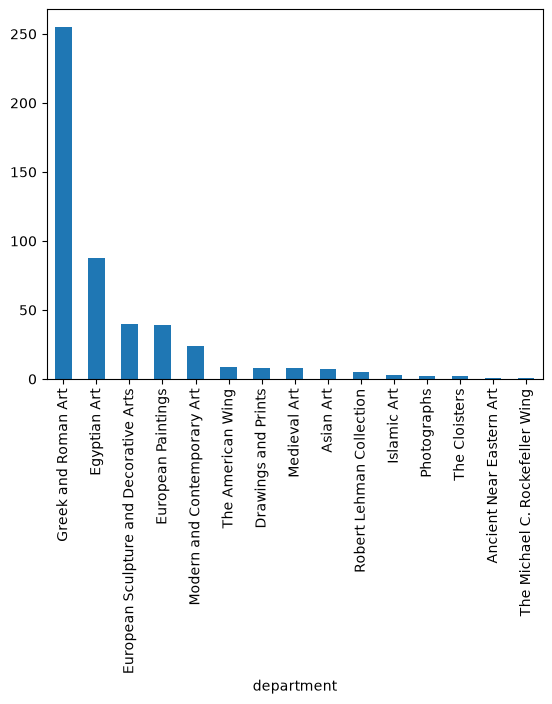

In [41]:
df.value_counts('department').plot(kind = 'bar')

A pie chart of the same counts:

<Axes: ylabel='count'>

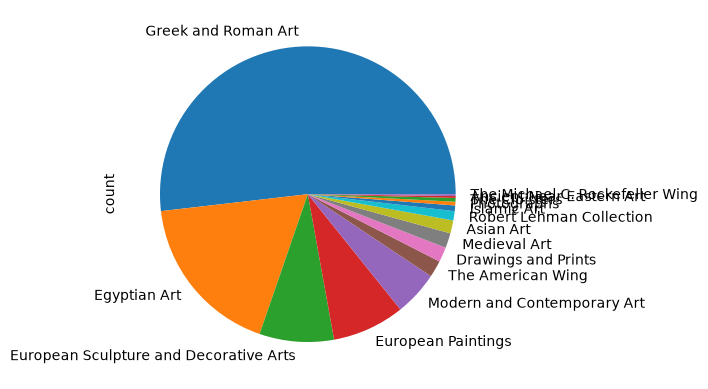

In [42]:
df.value_counts('department').plot(kind = 'pie')

A column with hundreds of different values, like `title`, makes an unreadable chart:

<Axes: xlabel='title'>

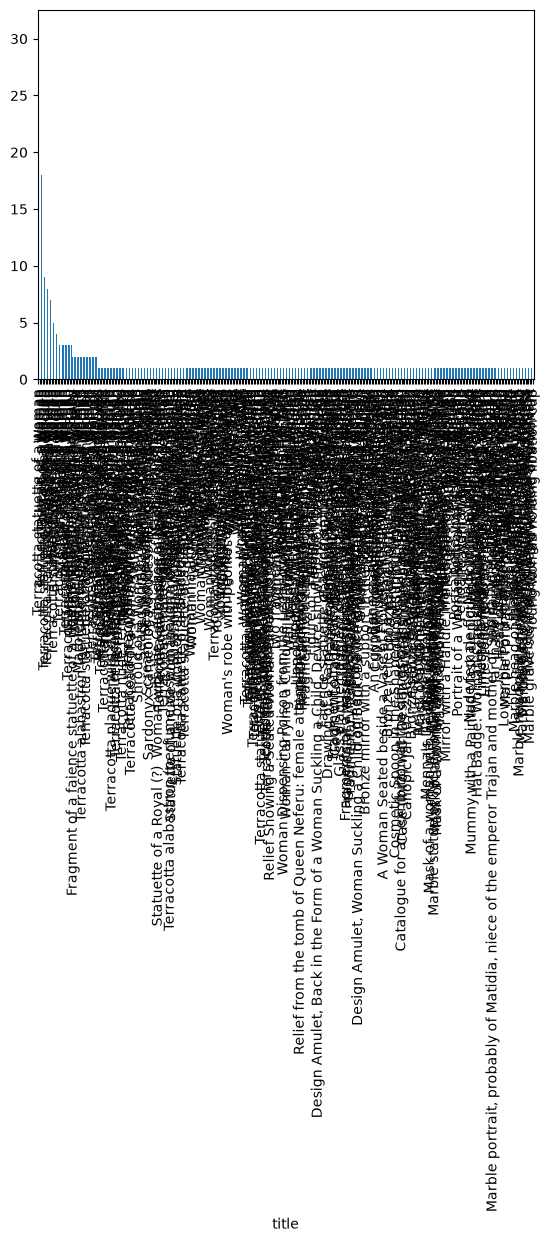

In [43]:
df.value_counts('title').plot(kind = 'bar')

`.nlargest(10)` keeps only the 10 largest values of a Series, so the chart stays readable:

<Axes: xlabel='title'>

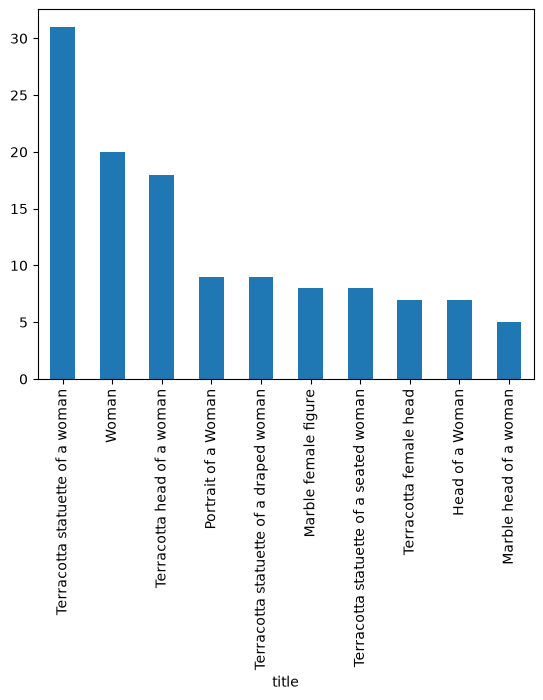

In [44]:
df.value_counts('title').nlargest(10).plot(kind = 'bar')

The same idea for artists. With long names, the labels crowd together:

<Axes: xlabel='artistDisplayName'>

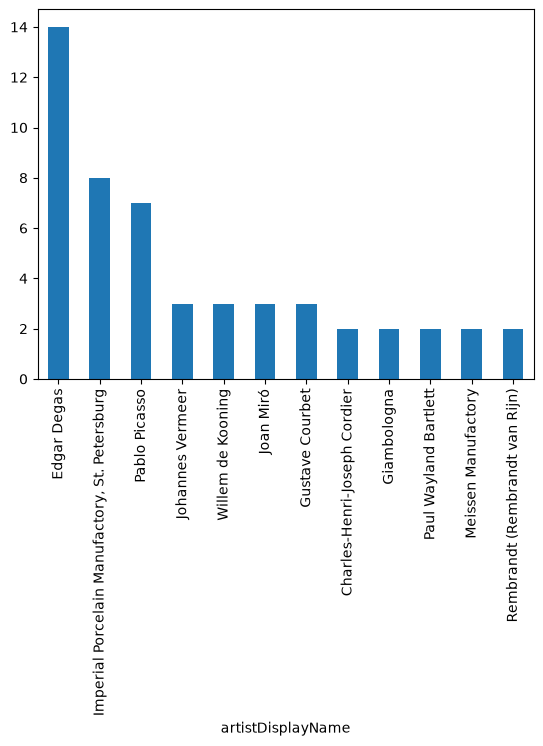

In [45]:
df.value_counts('artistDisplayName').nlargest(12).plot(kind = 'bar')

`kind='barh'` draws horizontal bars, so long labels fit. `title=` and `ylabel=` (and `xlabel=`) set the
chart's labels.

<Axes: title={'center': 'Works of "Women" at the MET'}, ylabel='Artist Name'>

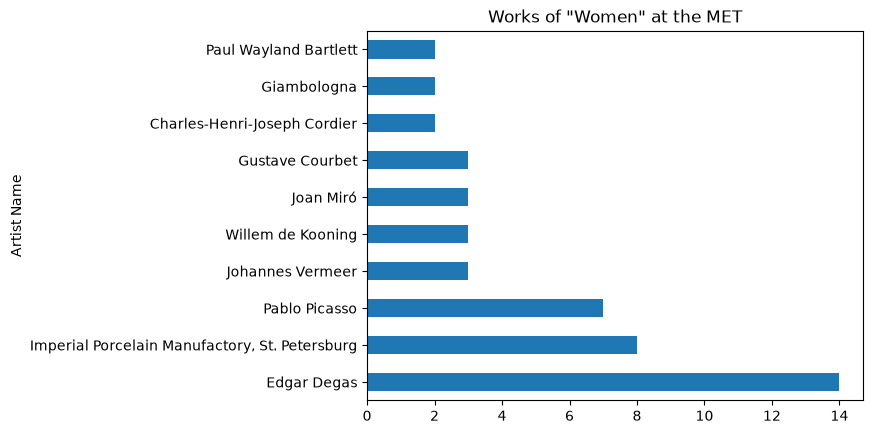

In [46]:
df.value_counts('artistDisplayName').nlargest(10).plot(kind='barh', ylabel='Artist Name', title='Works of "Women" at the MET')

Other plotting libraries:
- [Plotly](https://plotly.com/python/) - for creating interactive, web-based visualizations, supporting over 40 chart types including 3D plots and contour plots. Known for interactivity and dynamic visualizations. 
- [Seaborn](https://seaborn.pydata.org/) - offers built-in themes, color palettes and functions to easily create plots like bar charts, histograms, scatterplots and more. Known for simpler syntax. 